In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/embalses.csv", decimal=",", parse_dates=["FECHA"])

gq = df[
    (df["AMBITO_NOMBRE"] == "Guadalquivir")
    & (df["ELECTRICO_FLAG"] == 0)
    & (df["AGUA_TOTAL"] > 0)
].copy()

print(gq.shape)
print("Embalses:", gq["EMBALSE_NOMBRE"].nunique())

(90075, 6)
Embalses: 54


In [ ]:
#Ahora limpiamos los datos que no son reales. Negatrin 100 y Giribalde 5, que solo duran una semana y no son reales.

errores = (
    ((gq["EMBALSE_NOMBRE"] == "Negratín") & (gq["AGUA_TOTAL"] == 100))
    | ((gq["EMBALSE_NOMBRE"] == "Giribaile") & (gq["AGUA_TOTAL"] == 5))
)
print("Filas a eliminar:", errores.sum())

gq = gq[~errores]
print(gq.shape)

Filas a eliminar: 14
(90061, 6)


In [ ]:
#Unificamos La Breña y La Breña II como un solo nombre, para tratarlas como un solo embalse.

gq["EMBALSE_NOMBRE"] = gq["EMBALSE_NOMBRE"].replace("Breña II, La", "Breña, La")

breña = gq[gq["EMBALSE_NOMBRE"] == "Breña, La"]
print("Embalses:", gq["EMBALSE_NOMBRE"].nunique())
print("Fechas duplicadas en Breña:", breña["FECHA"].duplicated().sum())

Embalses: 53
Fechas duplicadas en Breña: 0


In [5]:
#Medimos cuánto supera los volumenes a la capacidad de los embalses para ver si hay alguno que sea incorrecto
gq["exceso"] = gq["AGUA_ACTUAL"] - gq["AGUA_TOTAL"]
sobre = gq[gq["exceso"] > 0]

print("Filas con exceso:", len(sobre))
print(sobre["exceso"].describe())
sobre.groupby("EMBALSE_NOMBRE")["exceso"].agg(["count", "max"]).sort_values("count", ascending=False).head(10)

Filas con exceso: 45
count    45.000000
mean      3.933333
std       3.114482
min       1.000000
25%       1.000000
50%       3.000000
75%       7.000000
max      10.000000
Name: exceso, dtype: float64


,count,max
EMBALSE_NOMBRE,,
"Pintado, El",30,10.0
Agrio (Aznalcollar),4,3.0
"Breña, La",4,4.0
Cordobilla,3,3.0
Fresneda,2,1.0
Montoro,1,10.0
Puente Nuevo,1,2.0


In [ ]:
#No vamos hacer nada con ellos, ya que parece ser datos reales, ya que el exceso máximo es de 10hm³

In [6]:
#Para varias fechas de inicio, contamos cuántos embalses tienen datos completos hasta hoy y qué parte de la capacidad acual representan, para 
#elegir el periodo con mejor equilibrio 

fin = gq["FECHA"].max()
cap_actual = gq[gq["FECHA"] == fin]["AGUA_TOTAL"].sum()

for inicio in ["1988-01-05", "1990-05-01", "1994-02-01", "1999-03-09", "2010-03-16"]:
    tramo = gq[gq["FECHA"] >= inicio]
    semanas = tramo["FECHA"].nunique()
    completos = tramo.groupby("EMBALSE_NOMBRE")["FECHA"].count()
    completos = completos[completos == semanas].index
    cap = gq[(gq["FECHA"] == fin) & gq["EMBALSE_NOMBRE"].isin(completos)]["AGUA_TOTAL"].sum()
    print(f"{inicio}: {len(completos)} embalses completos, {cap / cap_actual:.0%} de la capacidad actual")

1988-01-05: 24 embalses completos, 61% de la capacidad actual
1990-05-01: 29 embalses completos, 73% de la capacidad actual
1994-02-01: 37 embalses completos, 84% de la capacidad actual
1999-03-09: 39 embalses completos, 92% de la capacidad actual
2010-03-16: 45 embalses completos, 100% de la capacidad actual


In [7]:
#Nos quedamos con el periodo desde debrebero del 94, y solo con los embalses que tienen datos todas las semanas, sin La Breña, para que 
#el total de la cuenca no tenga saltos artificiales

INICIO = "1994-02-01" #Se puede cambiar en un futuro, ya que es una constante

tramo = gq[gq["FECHA"] >= INICIO]
semanas = tramo["FECHA"].nunique()

conteo = tramo.groupby("EMBALSE_NOMBRE")["FECHA"].count()
embalses_ok = conteo[conteo == semanas].index.drop("Breña, La")

gq_limpio = tramo[tramo["EMBALSE_NOMBRE"].isin(embalses_ok)].copy()

print("Embalses:", len(embalses_ok))
print("Semanas:", semanas)
print("Filas:", len(gq_limpio), "| esperadas:", len(embalses_ok) * semanas)

Embalses: 36
Semanas: 1708
Filas: 61488 | esperadas: 61488


           volumen    capacidad  pct_llenado
count  1708.000000  1708.000000  1708.000000
mean   3241.638759  5900.283372    54.903719
std    1325.330986    33.525820    22.387312
min     436.000000  5845.000000     7.417489
25%    2161.750000  5878.000000    36.721519
50%    3281.000000  5885.000000    55.414442
75%    4316.500000  5943.000000    73.160233
max    5622.000000  5943.000000    94.598688


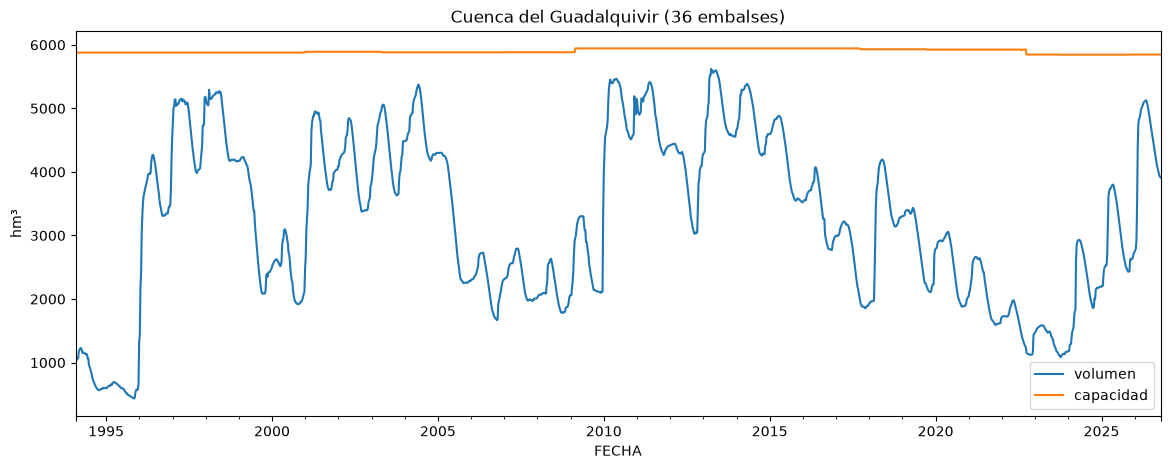

In [8]:
#Sumamos por semana el volumen y capacidad de los 36 embalses y calculamos el % de llenado, para obtener la serie de la cuenca con la que trabajaré el modelo.

import matplotlib.pyplot as plt

cuenca = gq_limpio.groupby("FECHA")[["AGUA_ACTUAL", "AGUA_TOTAL"]].sum()
cuenca.columns = ["volumen", "capacidad"]
cuenca["pct_llenado"] = cuenca["volumen"] / cuenca["capacidad"] * 100

print(cuenca.describe())
cuenca[["volumen", "capacidad"]].plot(figsize=(14, 5), title="Cuenca del Guadalquivir (36 embalses)")
plt.ylabel("hm³")
plt.show()

In [9]:
#Guardamos los datod limpios por embalse y la serie de la cuenca en Parquet, para que los siguientes notebooks parta de aqui sin repetir
#la limpieza

gq_limpio.to_parquet("../data/processed/embalses_guadalquivir.parquet", index=False)
cuenca.to_parquet("../data/processed/cuenca_semanal.parquet")

print(pd.read_parquet("../data/processed/cuenca_semanal.parquet").head())

            volumen  capacidad  pct_llenado
FECHA                                      
1994-02-01   1020.0     5878.0    17.352841
1994-02-08   1030.0     5878.0    17.522967
1994-02-15   1047.0     5878.0    17.812181
1994-02-22   1070.0     5878.0    18.203471
1994-03-01   1070.0     5878.0    18.203471
